# Recurrent Neural Networks for Time Series Forecasting

So far, each input to our models has been a fixed set of numbers (housing features, pixels).  But many problems involve sequences, where the order matters:
* daily sales
* sensor readings
* words in a sentence

We'll forecast daily ridership on Chicago's trains, using CTA data from the Chicago Data Portal: https://data.cityofchicago.org/

Here's the plan:
1. look at the data and set up a baseline that every model must beat
2. use sliding windows to turn a series into training examples
3. build a recurrent neural network (RNN) and see how it reads a sequence one step at a time
4. compare RNN, GRU, and LSTM in PyTorch
5. add better inputs:  bus ridership and the type of day
6. evaluate on the test set, and see what happens when the world changes (2020)

This follows Chapter 13 of Géron's *Hands-On Machine Learning* (PyTorch edition): https://github.com/ageron/handson-mlp

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("PyTorch", torch.__version__, "  device:", device)

PyTorch 2.15.0   device: mps


# The data and a baseline

Download the data (once) and read it with pandas.  Each row is one day:
* `day_type`: `W` = weekday, `A` = Saturday, `U` = Sunday or holiday
* `bus`, `rail`: the number of boardings that day

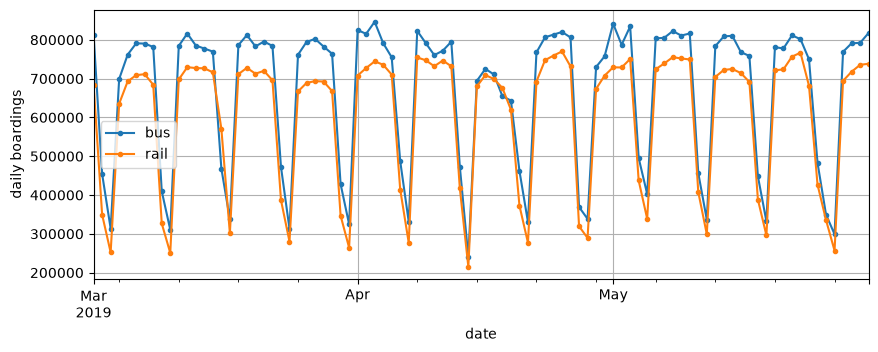

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


In [2]:
csv_path = Path("datasets/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv")
if not csv_path.is_file():
    Path("datasets").mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz", "datasets/ridership.tgz")
    with tarfile.open("datasets/ridership.tgz") as f:
        f.extractall(path="datasets", filter="data")

df = pd.read_csv(csv_path, parse_dates=["service_date"])
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date").drop("total", axis=1).drop_duplicates()

df[["bus", "rail"]]["2019-03":"2019-05"].plot(marker=".", figsize=(10, 3.5), grid=True)
plt.ylabel("daily boardings")
plt.show()
df.head()

Notice the strong weekly pattern -> high on weekdays, lower on Saturdays, lowest on Sundays.  Memorial Day (May 27, a Monday) looks like a Sunday.

## Baseline

Before building any model, we'll set up a baseline:  a simple forecast that needs no training.

Given the weekly pattern, a good one is the seasonal naive forecast, i.e., tomorrow will be like the same day last week.

We'll measure the mean absolute error (MAE), which tells us how many riders a forecast is off by, on average.

We split the series by date, never randomly.  A forecasting model must be judged on days that come *after* the days it learned from.
* training: 2016–2018
* validation: January to May 2019
* test: June to December 2019

In [3]:
rail = df["rail"]
valid_days = rail["2019-01":"2019-05"]
naive_forecast = rail.shift(7)["2019-01":"2019-05"]          # the value from 7 days earlier

results = {"naive (same day last week)": (valid_days - naive_forecast).abs().mean()}
print(f"naive validation MAE: {results['naive (same day last week)']:,.0f} riders")
print(f"average daily rail ridership: {valid_days.mean():,.0f}")

naive validation MAE: 64,815 riders
average daily rail ridership: 583,030


The naive forecast is good most days, but it makes big mistakes around holidays.  It also makes mistakes the week after each holiday, when it copies the holiday into an ordinary day.

For a model to be worth anything, it must beat this number.

# From a time series to training examples

A neural network needs inputs and targets.  We make them with a sliding window:  each example is the last 56 days (8 weeks), and its target is the next day.

```
days:    1  2  3 ... 56 | 57          <- example 1: input = days 1-56,  target = day 57
            2  3 ... 56   57 | 58     <- example 2: input = days 2-57,  target = day 58
```

Each example has to be cut out of the series, so we'll write our own `Dataset`.  It needs two methods:
* `__len__`: returns how many examples there are
* `__getitem__(i)`: returns example `i` as `(input, target)`

A `DataLoader` then works with it exactly as before.

In [4]:
class TimeSeriesDataset(Dataset):
    def __init__(self, series, window_length):
        self.series = series                     # tensor of shape (n_days, n_features)
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, i):
        window = self.series[i : i + self.window_length]     # (window_length, n_features)
        target = self.series[i + self.window_length, :1]     # next day's value of the FIRST column
        return window, target

# A tiny example: the "series" 0, 1, ..., 5 with windows of length 3
toy = TimeSeriesDataset(torch.arange(6.0).reshape(-1, 1), window_length=3)
for window, target in toy:
    print("window:", window.squeeze(1).tolist(), "  target:", target.tolist())

window: [0.0, 1.0, 2.0]   target: [3.0]
window: [1.0, 2.0, 3.0]   target: [4.0]
window: [2.0, 3.0, 4.0]   target: [5.0]


Now for the real datasets.  Two details:
* scaling -> we divide ridership by one million so values are around 0.5, a comfortable range for neural networks
* history -> each period starts 56 days before its first target day, so the first validation target (January 1, 2019) has a full window
  * this way, every model is scored on exactly the same days as the baseline

We'll build loaders twice (rail only now, more inputs later), so we'll put it in a function:

In [5]:
WINDOW = 56
SCALE = 1e6

def window_dataset(features, first_target, last_target):
    start = pd.Timestamp(first_target) - pd.Timedelta(days=WINDOW)    # include 56 days of history
    return TimeSeriesDataset(torch.tensor(features.loc[start:last_target].values, dtype=torch.float32), WINDOW)

def make_loaders(features):
    torch.manual_seed(42)
    train_loader = DataLoader(window_dataset(features, "2016-01-01", "2018-12-31"), batch_size=32, shuffle=True)
    valid_loader = DataLoader(window_dataset(features, "2019-01-01", "2019-05-31"), batch_size=256)
    test_loader = DataLoader(window_dataset(features, "2019-06-01", "2019-12-31"), batch_size=256)
    return train_loader, valid_loader, test_loader

train_loader, valid_loader, test_loader = make_loaders(df[["rail"]] / SCALE)
X_batch, y_batch = next(iter(train_loader))
print("input batch:", X_batch.shape, "  target batch:", y_batch.shape)

input batch: torch.Size([32, 56, 1])   target batch: torch.Size([32, 1])


The input has shape `(batch, time steps, features)` = `(32, 56, 1)`, i.e., 32 windows of 56 days, with 1 number per day.  This is the standard shape for sequences.

Side note:
* shuffling the training windows is fine, since each window still holds consecutive days
* what we must never do is mix days between the training, validation, and test periods

## Training loop

This is the same loop as before, with Adam and MSE loss.  Two small additions:
* we report the MAE in riders
* we keep the parameters from the epoch with the lowest validation error (validation error jumps around from epoch to epoch)

In [6]:
def mae_in_riders(model, loader):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            total += (model(X) - y).abs().sum().item()
            n += y.numel()
    return total / n * SCALE

def fit(model, train_loader, valid_loader, n_epochs=50, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_mae = float("inf")
    for epoch in range(n_epochs):
        model.train()
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            loss = nn.functional.mse_loss(model(X), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        mae = mae_in_riders(model, valid_loader)
        if mae < best_mae:                                         # keep the best epoch
            best_mae, best_state = mae, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f"best validation MAE: {best_mae:,.0f} riders")
    return best_mae

# A recurrent neural network

A recurrent neural network reads the sequence one day at a time, keeping a hidden state $h$.  This is a vector that summarizes what it has seen so far.

At each step $t$, it combines the new input $x_t$ with the previous hidden state:

$$h_t = \tanh(W_x\, x_t + W_h\, h_{t-1} + b)$$

The same weights are used at every step, much like a convolutional filter is reused at every position of an image.  After the last day, a linear layer turns the final hidden state into a forecast:

```
h0 = 0 ─► [cell] ─► h1 ─► [cell] ─► h2 ─► ... ─► [cell] ─► h56 ─► Linear ─► forecast
            ▲                ▲                      ▲
            x1               x2                     x56
```

PyTorch's `nn.RNN` implements this loop:

```python
rnn = nn.RNN(input_size, hidden_size, batch_first=True)   # batch_first: input is (batch, time, features)
outputs, h_last = rnn(X)                                  # outputs: the hidden state at EVERY step
```

There's no magic here.  To see that, let's write the loop ourselves using `nn.RNN`'s own weights and check that we get the same answer.

Technical note: PyTorch stores $W_x$ as `weight_ih_l0`, $W_h$ as `weight_hh_l0`, and splits $b$ into two bias vectors.

In [7]:
torch.manual_seed(42)
rnn = nn.RNN(input_size=1, hidden_size=32, batch_first=True)

def rnn_by_hand(X):                                  # X: (batch, time, features)
    h = torch.zeros(X.shape[0], 32)                  # h0 = 0
    for t in range(X.shape[1]):                      # one day at a time, same weights at every step
        x_t = X[:, t]
        h = torch.tanh(x_t @ rnn.weight_ih_l0.T + h @ rnn.weight_hh_l0.T + rnn.bias_ih_l0 + rnn.bias_hh_l0)
    return h

outputs, h_last = rnn(X_batch)
print("outputs:", outputs.shape, "  (batch, time, hidden_size)")
print("our loop matches nn.RNN:", torch.allclose(rnn_by_hand(X_batch), outputs[:, -1], atol=1e-5))
print("parameters:", sum(p.numel() for p in rnn.parameters()), " (doesn't depend on the sequence length)")

outputs: torch.Size([32, 56, 32])   (batch, time, hidden_size)
our loop matches nn.RNN: True
parameters: 1120  (doesn't depend on the sequence length)


# RNN, GRU, and LSTM

A plain RNN has trouble remembering things for many steps:
* the hidden state is overwritten at every step
* during training, the gradients flowing back through many steps tend to shrink toward zero

Two improved cells fix this with gates.  These are small learned switches that decide what to keep, what to forget, and what to add at each step.
* LSTM (long short-term memory, 1997) keeps a separate long-term memory alongside the hidden state
* GRU (gated recurrent unit, 2014) is a simpler variant that often works as well

They're drop-in replacements, so one model class can handle all three.  The forecast comes from the hidden state after the last day, `outputs[:, -1]`.

In [8]:
class RecurrentModel(nn.Module):
    def __init__(self, cell_type, input_size, hidden_size=32):
        super().__init__()
        layer = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[cell_type]
        self.rnn = layer(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, _ = self.rnn(X)              # (batch, time, hidden_size)
        return self.output(outputs[:, -1])    # forecast from the hidden state after the last day

for cell_type in ["RNN", "GRU", "LSTM"]:
    print(cell_type, end=": ")
    torch.manual_seed(42)
    model = RecurrentModel(cell_type, input_size=1).to(device)
    results[cell_type] = fit(model, train_loader, valid_loader)

RNN: best validation MAE: 45,366 riders
GRU: best validation MAE: 40,606 riders
LSTM: best validation MAE: 44,979 riders


In [9]:
def show_results():
    for name, mae in sorted(results.items(), key=lambda item: -item[1]):
        print(f"{name:28s} {mae:9,.0f}")

show_results()

naive (same day last week)      64,815
RNN                             45,366
LSTM                            44,979
GRU                             40,606


All three recurrent models beat the baseline!

Which cell wins varies from problem to problem (and even with the random seed), so in practice people try more than one.  GRUs are a good default.

# Better inputs:  bus ridership and the type of day

The biggest errors happen around holidays, and nothing in the rail numbers says that tomorrow is a holiday.  But the calendar is known in advance!

So for each day in the window, we'll give the model:
* rail ridership (still the first column, so it remains the target)
* bus ridership
* the *next* day's type, one-hot encoded as three columns: `A` (Saturday), `U` (Sunday/holiday), `W` (weekday)

Each time step now has 5 features instead of 1.  On the last day of the window, "next day's type" tells the model what kind of day it is forecasting.

In [10]:
multi = df[["rail", "bus"]] / SCALE
multi["next_day_type"] = df["day_type"].shift(-1)          # tomorrow's type
multi = pd.get_dummies(multi, columns=["next_day_type"], dtype=float)
print(multi.head())

multi_train_loader, multi_valid_loader, multi_test_loader = make_loaders(multi)

torch.manual_seed(42)
multi_gru = RecurrentModel("GRU", input_size=5).to(device)     # the only change: input_size=5
results["GRU + bus + day type"] = fit(multi_gru, multi_train_loader, multi_valid_loader)
show_results()

                rail       bus  next_day_type_A  next_day_type_U  \
date                                                               
2001-01-01  0.126455  0.297192              0.0              0.0   
2001-01-02  0.501952  0.780827              0.0              0.0   
2001-01-03  0.536432  0.824923              0.0              0.0   
2001-01-04  0.550011  0.870021              0.0              0.0   
2001-01-05  0.557917  0.890426              1.0              0.0   

            next_day_type_W  
date                         
2001-01-01              1.0  
2001-01-02              1.0  
2001-01-03              1.0  
2001-01-04              1.0  
2001-01-05              0.0  
best validation MAE: 35,636 riders
naive (same day last week)      64,815
RNN                             45,366
LSTM                            44,979
GRU                             40,606
GRU + bus + day type            35,636


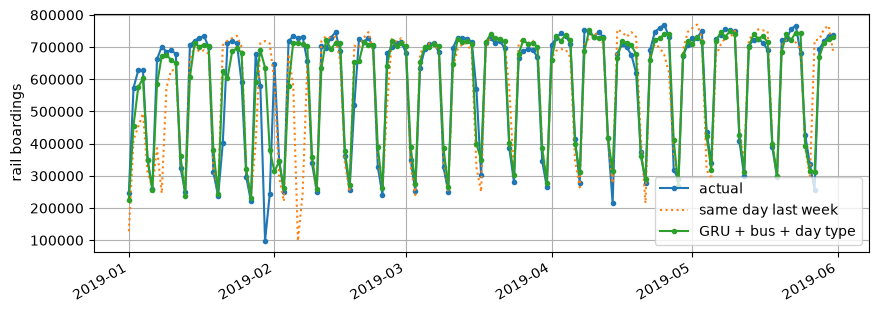

In [11]:
multi_gru.eval()
with torch.no_grad():
    gru_forecast = torch.cat([multi_gru(X.to(device)).cpu() for X, _ in multi_valid_loader]).squeeze(1) * SCALE

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(valid_days.index, valid_days.values, ".-", label="actual")
ax.plot(valid_days.index, naive_forecast.values, ":", label="same day last week")
ax.plot(valid_days.index, gru_forecast, ".-", label="GRU + bus + day type")
ax.grid(); ax.legend(); ax.set_ylabel("rail boardings")
fig.autofmt_xdate()
plt.show()

Knowing the calendar fixes most of the holiday errors.

What about the deep dip at the end of January?  That's the "polar vortex" cold snap of January 30, 2019.  No forecast based on past ridership can see that coming.

A lesson that applies well beyond neural networks -> the right input features often matter more than the choice of model.

# The test set, and when the world changes

We chose our best model using the validation set, so its validation score is a little optimistic.  The test set (June to December 2019) gives an honest final check:

In [12]:
test_days = rail["2019-06":"2019-12"]
print(f"naive (last week)      test MAE: {(test_days - rail.shift(7)['2019-06':'2019-12']).abs().mean():9,.0f}")
print(f"GRU + bus + day type   test MAE: {mae_in_riders(multi_gru, multi_test_loader):9,.0f}")

naive (last week)      test MAE:    62,949
GRU + bus + day type   test MAE:    26,814


Our model learned from 2016–2018.  What happens if we use it from March to June 2020, as the pandemic shut down the city?

naive (last week) MAE:    36,282
GRU MAE:                  86,866


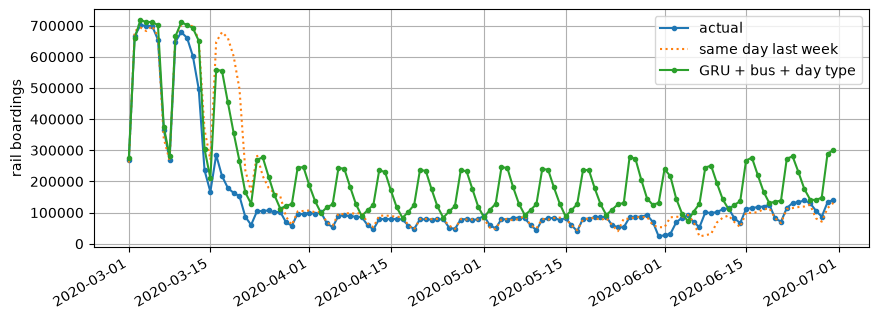

In [13]:
covid_loader = DataLoader(window_dataset(multi, "2020-03-01", "2020-06-30"), batch_size=256)
covid_days = rail["2020-03-01":"2020-06-30"]
covid_naive = rail.shift(7)["2020-03-01":"2020-06-30"]
multi_gru.eval()
with torch.no_grad():
    covid_forecast = torch.cat([multi_gru(X.to(device)).cpu() for X, _ in covid_loader]).squeeze(1) * SCALE

print(f"naive (last week) MAE: {(covid_days - covid_naive).abs().mean():9,.0f}")
print(f"GRU MAE:               {mae_in_riders(multi_gru, covid_loader):9,.0f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(covid_days.index, covid_days.values, ".-", label="actual")
ax.plot(covid_days.index, covid_naive.values, ":", label="same day last week")
ax.plot(covid_days.index, covid_forecast, ".-", label="GRU + bus + day type")
ax.grid(); ax.legend(); ax.set_ylabel("rail boardings")
fig.autofmt_xdate()
plt.show()

As ridership collapses in mid-March, both forecasts lag far behind.
* the naive forecast recovers within a week, since it just copies last week, whatever the level
* the GRU keeps producing the weekday/weekend swings it learned from normal years, around a level it has never seen

Nothing in its training data looked like this.

This is called distribution shift:  the data no longer behaves like the data the model learned from.

Every forecasting model assumes the future resembles the past.  That's why, in practice, models are monitored and retrained as new data arrives.

# Summary

* start with a baseline
  * for data with a strong weekly pattern, "same day last week" is hard to beat
* split time series by date, and evaluate on days after the training data
* a sliding window and a custom `Dataset` turn a series into examples of shape `(batch, time, features)`
* an RNN reads a sequence one step at a time, updating a hidden state with the same weights at every step
  * GRU and LSTM cells add gates that help them remember over longer spans
* better inputs (knowing the type of day) can matter more than a better model
* when the future stops resembling the past (distribution shift), models fail